# Grape Bunch Detection & Counting - Vineyard Deployment
### YOLO11 Object Detection - Domain-Gap-Aware Training Mix - SAHI Tiled Inference - Manual Ground-Truth Annotation

**Task:** detect and count grape bunches in real farm photos (single class: `bunch`).

**Data sources:**
- **"Online" dataset** (6028/2002/1980 train/val/test images) - single centered bunch per photo, large boxes, blurry. Sourced as generic "grape bunch" web images.
- **WGISD** (Wine Grape Instance Segmentation Dataset, red/black cultivars) - many small bunches per photo, sharp, real vineyard rows.
- **Live farm photos** (43 images) - real camera photos from an actual farm. Unlabeled until Phase 3 of this notebook.

**Why this rewrite exists:** the previous training run scored MAE 0.14 on the online in-distribution test set but MAE 1.34 (24% exact-match) on the WGISD holdout, and was never numerically evaluated on real farm photos at all - only eyeballed. Phase 1's EDA shows why: the online dataset does not resemble the deployment domain (single large centered bunch vs. many small occluded bunches scattered across a wide frame). This notebook quantifies that domain gap, rebalances training around it, adds SAHI tiled inference for the high-resolution farm photos, and builds a small hand-labeled real-photo holdout so "does it work in the field" finally has a number attached to it.

**Notebook scope:**
- **Phases 0-2** only need the 43 real farm photos and run on any machine with the images available locally - use them to sanity-check preprocessing before spending Colab GPU time.
- **Phases 3-7** need Google Drive (online dataset + WGISD), a GPU runtime, and - for Phase 3.1 - a few minutes of manual clicking to build the labeled holdout.

# Phase 0 - Environment Setup

## 0.0 Mount Drive & Confirm GPU

`ROOT` is the single source of truth for all persisted data, configs, and model runs.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import torch, subprocess
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU -- check runtime type")
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv"], capture_output=True, text=True).stdout)

ROOT = "/content/drive/MyDrive/GrapeBunchDetection"
import os
for p in [
    "data/raw/online_dataset", "data/raw/live_images",
    "data/processed", "data/eval",
    "data/annotations/live_holdout/images", "data/annotations/live_holdout/labels",
    "runs", "configs", "notebooks",
]:
    os.makedirs(f"{ROOT}/{p}", exist_ok=True)
print("Workspace ready at:", ROOT)

### Local Alternative (No Drive Mount) -- Use the Local `data/` Folder

Run this cell **instead of** the one above if you are not in Colab, or don't have the online dataset
and WGISD staged in Google Drive yet. It skips `drive.mount(...)` entirely and points `ROOT` at a local
workspace next to the notebook, with `LIVE_DIR` pointed directly at the `data/` folder already in this
repo (the 43 real farm photos) -- enough for Phases 0-2 (environment setup and the image-preprocessing
pipeline) to run end-to-end with no Drive and no GPU required.

`ONLINE_BASE` and the WGISD clone still assume the online dataset / WGISD are reachable at their
configured paths -- Phase 1.2 onward (WGISD clone), Phase 1.3 (online remap), and everything downstream
of them will need either Colab + Drive, or local copies of those datasets placed at the same paths,
before they can run.

In [1]:
# --- Local alternative: skip Google Drive, use the repo's local data/ folder ---
import torch, subprocess
from pathlib import Path

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU -- CPU only")
try:
    print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv"], capture_output=True, text=True).stdout)
except FileNotFoundError:
    print("nvidia-smi not found -- running on CPU-only or non-NVIDIA hardware.")

ROOT = str(Path.cwd())                  # local workspace: this notebook's own folder
LIVE_DIR = str(Path.cwd() / "data")     # the 43 real farm photos already in this repo

import os
for p in [
    "data/raw/online_dataset", "data/processed", "data/eval",
    "data/annotations/live_holdout/images", "data/annotations/live_holdout/labels",
    "runs", "configs", "notebooks",
]:
    os.makedirs(f"{ROOT}/{p}", exist_ok=True)

n_live = len(list(Path(LIVE_DIR).glob("*.*")))
print("Workspace ready at:", ROOT)
print(f"Live farm photos: {n_live} images at {LIVE_DIR}")
print("NOTE: the online dataset and WGISD are not available locally -- Phase 1.2 onward (WGISD clone),")
print("      Phase 1.3 (online remap), and anything downstream of them will need Colab + Drive,")
print("      or local copies placed at ONLINE_BASE / WGISD_DIR before running.")

GPU: NO GPU -- CPU only
name, memory.total [MiB]
NVIDIA GeForce RTX 4070 Ti, 12282 MiB

Workspace ready at: c:\Users\lehoa\Downloads\GrapeBunchDetection\Deep Learning
Live farm photos: 0 images at c:\Users\lehoa\Downloads\GrapeBunchDetection\Deep Learning\data
NOTE: the online dataset and WGISD are not available locally -- Phase 1.2 onward (WGISD clone),
      Phase 1.3 (online remap), and anything downstream of them will need Colab + Drive,
      or local copies placed at ONLINE_BASE / WGISD_DIR before running.


## 0.1 Install Packages

In [4]:
# !pip install -q ultralytics sahi ipympl ipywidgets grad-cam
import ultralytics
ultralytics.checks()

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass  # not running in Colab -- no custom widget manager needed locally

Ultralytics 8.4.120  Python-3.14.7 torch-2.13.0+cpu CPU (12th Gen Intel Core i9-12900K)
Setup complete  (24 CPUs, 31.7 GB RAM, 975.0/1104.1 GB disk)


## 0.2 Smoke-Test the Interactive Widget Backend & SAHI

Fail fast here instead of mid-notebook: confirm the `ipympl` widget backend renders (needed for Phase 3's
manual annotation tool) and that SAHI's model wrapper imports cleanly (needed for Phase 5's tiled inference).

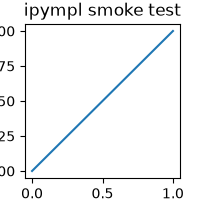

If an interactive plot rendered above (not a static image), the widget backend is working.
SAHI import OK: <class 'sahi.auto_model.AutoDetectionModel'> <function get_sliced_prediction at 0x00000169158FADA0>


In [5]:
%matplotlib widget
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(2, 2))
ax.plot([0, 1], [0, 1])
ax.set_title("ipympl smoke test")
plt.show()
print("If an interactive plot rendered above (not a static image), the widget backend is working.")

from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction
print("SAHI import OK:", AutoDetectionModel, get_sliced_prediction)

## 0.3 Global Configuration

Seeds, class list, path constants, and the data-mix / tiling constants used throughout the notebook.
Changing a value here (e.g. `K_OVERSAMPLE`) is the single edit point for re-running downstream phases
with a different configuration.

In [6]:
import random
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

CLASS_NAMES = ["bunch"]
NUM_CLASSES = len(CLASS_NAMES)

# Data source roots
ONLINE_BASE = f"{ROOT}/data/raw/online_dataset/GrapevineBunchDetection"
WGISD_DIR = "/content/wgisd"
LIVE_DIR = f"{ROOT}/data/raw/live_images/LiveImages"
WGISD_PREFIXES = ("CFR_", "CSV_", "SYH_")

# Local working copy (fast disk, not Drive) for the merged/remapped dataset
LOCAL_DATA = "/content/data/processed"

# Training / tiling constants
TRAIN_IMGSZ = 1024          # native tile size for both training and SAHI slices
TILE_SIZE = 1024
TILE_OVERLAP = 0.25         # SAHI overlap_height/width_ratio
WGISD_DEV_N = 20            # reserved from the 141 WGISD train-eligible images, for checkpoint selection only
K_OVERSAMPLE = 8            # WGISD repeat factor in the training file list
TARGET_WGISD_SHARE = 0.5    # target share of the effective training epoch that should be WGISD-domain

print("Config set. Classes:", CLASS_NAMES)

Config set. Classes: ['bunch']


In [7]:
import cv2
from pathlib import Path

def sharpness(img_path, resize_to=1024):
    """Laplacian-variance blur/sharpness score, scale-normalized so resolution alone doesn't confound the comparison."""
    im = cv2.imread(str(img_path))
    if im is None:
        return None
    h, w = im.shape[:2]
    scale = resize_to / max(h, w)
    im = cv2.resize(im, (int(w * scale), int(h * scale)))
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var()

def box_area_frac(yolo_line):
    """Normalized box area (w*h) from a single YOLO-format label line."""
    _, cx, cy, w, h = map(float, yolo_line.split())
    return w * h

print("Helpers ready: sharpness(), box_area_frac()")

Helpers ready: sharpness(), box_area_frac()


# Phase 1 - Dataset Preparation & EDA

## 1.1 Inspect Raw Dataset Structure

Confirm the expected folder layout is present in Drive before doing any real work.

In [8]:
def count_files(path, ext=None):
    p = Path(path)
    if not p.is_dir():
        return "MISSING"
    files = list(p.iterdir())
    if ext:
        files = [f for f in files if f.suffix.lower() in ext]
    return len(files)

print("online_dataset structure:")
for split in ["train", "val", "test"]:
    for kind in ["images", "labels"]:
        print(f"  {split}/{kind}: {count_files(f'{ONLINE_BASE}/{split}/{kind}')} files")

print("\nlive_images:", count_files(LIVE_DIR), "files")

online_dataset structure:
  train/images: MISSING files
  train/labels: MISSING files
  val/images: MISSING files
  val/labels: MISSING files
  test/images: MISSING files
  test/labels: MISSING files

live_images: MISSING files


## 1.2 Bring In WGISD

WGISD (Wine Grape Instance Segmentation Dataset) supplies the multi-bunch, small-box, sharp-photo
domain the online dataset lacks. Clone it, then filter to the red/black cultivars (`CFR_`, `CSV_`,
`SYH_` prefixes) which are visually closest to the dark-fruit farm photos we ultimately care about.

In [9]:
import subprocess, time

t0 = time.time()
subprocess.run(["git", "clone", "--depth", "1", "https://github.com/thsant/wgisd.git", WGISD_DIR], check=True)
print(f"Cloned WGISD in {time.time()-t0:.1f}s")

Cloned WGISD in 86.3s


### Validate WGISD's Label Format Before Trusting It

The previous notebook merged WGISD's `.txt` labels straight into training without ever checking
their format matched the assumed normalized `class cx cy w h` convention. If it were actually pixel
`x1 y1 x2 y2`, or un-normalized, every box below would land wildly off the actual grapes. Parse a
handful of label files with that assumption and overlay the boxes -- if they hug real bunches, the
assumption is confirmed; if not, this is caught here instead of silently corrupting training.

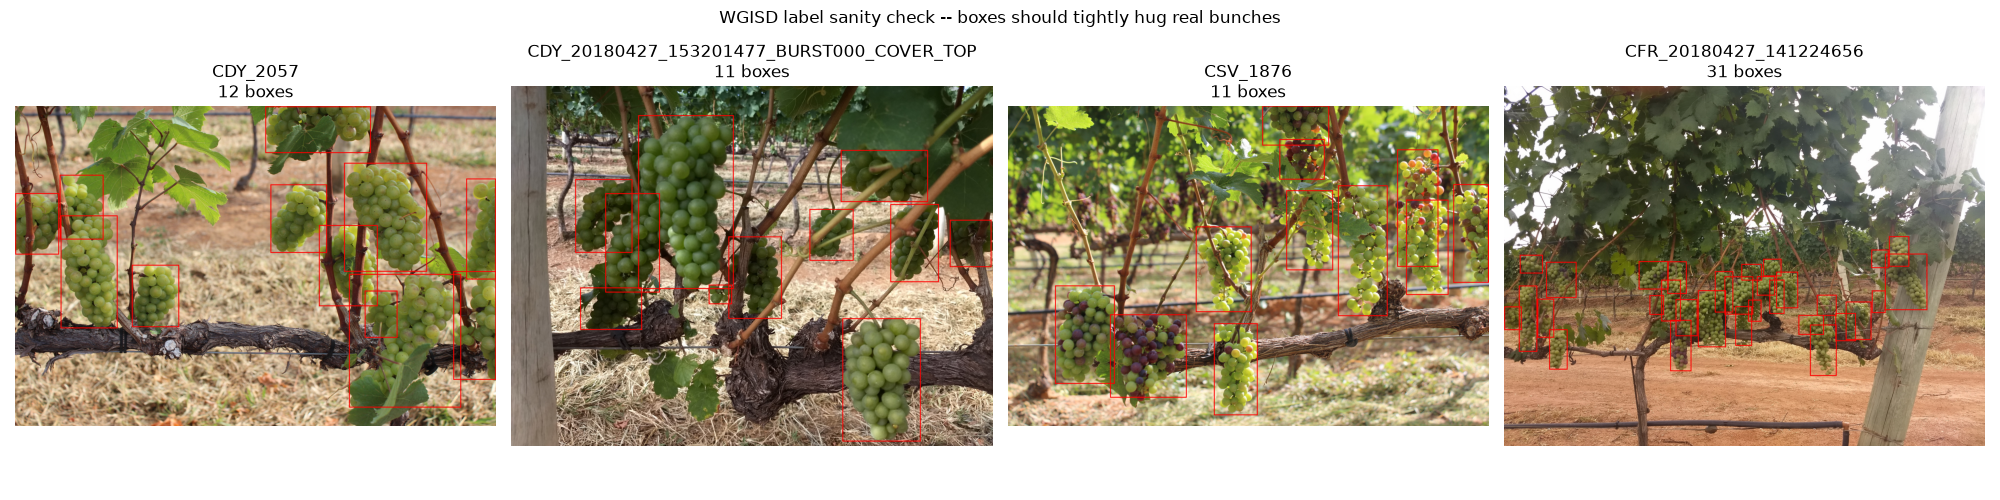

If boxes above sit correctly on bunches, the normalized 'class cx cy w h' format is confirmed for training use.


In [10]:
import random
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

def overlay_yolo_boxes(img_path, label_path, color="red"):
    im = Image.open(img_path).convert("RGB")
    draw = ImageDraw.Draw(im)
    w, h = im.size
    n = 0
    for line in open(label_path):
        if not line.strip():
            continue
        _, cx, cy, bw, bh = map(float, line.split())
        x1, y1 = (cx - bw / 2) * w, (cy - bh / 2) * h
        x2, y2 = (cx + bw / 2) * w, (cy + bh / 2) * h
        draw.rectangle([x1, y1, x2, y2], outline=color, width=4)
        n += 1
    return im, n

wgisd_label_files = list(Path(WGISD_DIR, "data").glob("*.txt"))
picks = random.sample(wgisd_label_files, 4)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, lf in zip(axes, picks):
    img_matches = [p for p in Path(WGISD_DIR, "data").glob(lf.stem + ".*") if p.suffix.lower() in (".jpg", ".jpeg", ".png")]
    im, n = overlay_yolo_boxes(img_matches[0], lf)
    ax.imshow(im); ax.axis("off"); ax.set_title(f"{lf.stem}\n{n} boxes")
plt.suptitle("WGISD label sanity check -- boxes should tightly hug real bunches")
plt.tight_layout(); plt.show()
print("If boxes above sit correctly on bunches, the normalized 'class cx cy w h' format is confirmed for training use.")

## 1.3 Build a Local Working Copy & Remap Labels to a Single Class

Both sources may encode multiple classes/cultivars in their label files, but this project only cares
about detecting a bunch as a single class. Copy images from Drive to fast local disk while rewriting
every label line to class id `0` (`bunch`) in the same pass.

In [11]:
import shutil, time
from tqdm import tqdm

def remap_split_from_drive(split):
    """Copy Drive images + remap labels to single class 0, directly onto local fast disk."""
    src_img, src_lbl = Path(ONLINE_BASE, split, "images"), Path(ONLINE_BASE, split, "labels")
    dst_img, dst_lbl = Path(LOCAL_DATA, split, "images"), Path(LOCAL_DATA, split, "labels")
    dst_img.mkdir(parents=True, exist_ok=True)
    dst_lbl.mkdir(parents=True, exist_ok=True)

    for lf in tqdm(list(src_lbl.glob("*.txt")), desc=split):
        img_matches = list(src_img.glob(lf.stem + ".*"))
        if not img_matches:
            print("WARNING: no image for", lf.name)
            continue
        shutil.copy(img_matches[0], dst_img / img_matches[0].name)
        lines_out = []
        for line in open(lf):
            parts = line.split()
            if not parts:
                continue
            _, cx, cy, w, h = parts
            lines_out.append(f"0 {cx} {cy} {w} {h}")
        with open(dst_lbl / lf.name, "w") as f:
            f.write("\n".join(lines_out) + "\n")

t0 = time.time()
for split in ["train", "val", "test"]:
    remap_split_from_drive(split)
print(f"Remap done in {time.time()-t0:.1f}s")

train: 0it [00:00, ?it/s]
val: 0it [00:00, ?it/s]
test: 0it [00:00, ?it/s]

Remap done in 0.0s


In [12]:
for split in ["train", "val", "test"]:
    img_c = len(os.listdir(Path(LOCAL_DATA, split, "images")))
    lbl_c = len(os.listdir(Path(LOCAL_DATA, split, "labels")))
    print(split, "images:", img_c, "labels:", lbl_c)

classes_found = set()
for split in ["train", "val", "test"]:
    for lf in Path(LOCAL_DATA, split, "labels").glob("*.txt"):
        for line in open(lf):
            if line.strip():
                classes_found.add(line.split()[0])
print("Classes found after remap:", classes_found)

train images: 0 labels: 0
val images: 0 labels: 0
test images: 0 labels: 0
Classes found after remap: set()


## 1.4 Integrate WGISD -- Train Pool / Dev / Test Holdout

WGISD's own `train.txt`/`test.txt` stem lists get split three ways:

- **Train pool** -- merged into the main train set, oversampled per the mix formula built later in this phase.
- **Dev slice** (20 images) -- held out for checkpoint selection during training, so the oversampled pool never
  influences early stopping (oversampling *and* using the same images for early-stopping would let the model
  memorize its way to a falsely good validation score).
- **Test holdout** (WGISD's original test stems) -- never trained on, used only for final domain-gap evaluation
  in Phase 5.

In [13]:
WGISD = Path(WGISD_DIR)

def load_stems(txt_path):
    return [l.strip() for l in open(txt_path) if l.strip()]

def red_black(stems):
    return [s for s in stems if s.startswith(WGISD_PREFIXES)]

train_stems_all = red_black(load_stems(WGISD / "train.txt"))
test_stems = red_black(load_stems(WGISD / "test.txt"))

random.Random(SEED).shuffle(train_stems_all)
dev_stems = train_stems_all[:WGISD_DEV_N]
pool_stems = train_stems_all[WGISD_DEV_N:]

print(f"WGISD red/black: {len(train_stems_all)} train-eligible -> {len(pool_stems)} train pool + {len(dev_stems)} dev")
print(f"WGISD test holdout (untouched): {len(test_stems)}")

def copy_stems(stems, dst_img_dir, dst_lbl_dir):
    dst_img_dir = Path(dst_img_dir); dst_lbl_dir = Path(dst_lbl_dir)
    dst_img_dir.mkdir(parents=True, exist_ok=True)
    dst_lbl_dir.mkdir(parents=True, exist_ok=True)
    copied = 0
    for stem in stems:
        img_matches = [p for p in (WGISD / "data").glob(stem + ".*") if p.suffix.lower() in (".jpg", ".jpeg", ".png")]
        lbl_path = WGISD / "data" / f"{stem}.txt"
        if not img_matches or not lbl_path.exists():
            print("WARNING: missing image or label for", stem)
            continue
        shutil.copy(img_matches[0], dst_img_dir / img_matches[0].name)
        shutil.copy(lbl_path, dst_lbl_dir / lbl_path.name)
        copied += 1
    return copied

POOL_DIR = Path(LOCAL_DATA, "wgisd_pool")
DEV_DIR = Path("/content/data/eval/wgisd_dev")
HOLDOUT_DIR = Path("/content/data/eval/wgisd_holdout")

n_pool = copy_stems(pool_stems, POOL_DIR / "images", POOL_DIR / "labels")
n_dev = copy_stems(dev_stems, DEV_DIR / "images", DEV_DIR / "labels")
n_holdout = copy_stems(test_stems, HOLDOUT_DIR / "images", HOLDOUT_DIR / "labels")
print(f"Copied: pool={n_pool} dev={n_dev} holdout={n_holdout}")

WGISD red/black: 141 train-eligible -> 121 train pool + 20 dev
WGISD test holdout (untouched): 29
Copied: pool=121 dev=20 holdout=29


In [14]:
pool_stem_set = {p.stem for p in (POOL_DIR / "images").glob("*.*")}
dev_stem_set = {p.stem for p in (DEV_DIR / "images").glob("*.*")}
holdout_stem_set = {p.stem for p in (HOLDOUT_DIR / "images").glob("*.*")}

print("pool/dev overlap (must be 0):", len(pool_stem_set & dev_stem_set))
print("pool/holdout overlap (must be 0):", len(pool_stem_set & holdout_stem_set))
print("dev/holdout overlap (must be 0):", len(dev_stem_set & holdout_stem_set))
assert not (pool_stem_set & dev_stem_set) and not (pool_stem_set & holdout_stem_set) and not (dev_stem_set & holdout_stem_set), "LEAK detected between WGISD splits"
print("No leakage between WGISD pool / dev / holdout.")

pool/dev overlap (must be 0): 0
pool/holdout overlap (must be 0): 0
dev/holdout overlap (must be 0): 0
No leakage between WGISD pool / dev / holdout.


## 1.5 Per-Source EDA -- Bunches/Image, Box Size, Sharpness

This is the evidence base for the domain-mismatch diagnosis this whole rewrite is built around.
Compute the same three statistics for every source: how many bunches appear per image, how much of
the frame a typical box covers, and how sharp (in-focus) the photo is.

In [17]:
def source_stats(label_dir, image_dir, n_sharp=20):
    label_dir, image_dir = Path(label_dir), Path(image_dir)
    counts, areas = [], []
    for lf in label_dir.glob("*.txt"):
        lines = [l for l in open(lf) if l.strip()]
        counts.append(len(lines))
        areas.extend(box_area_frac(l) for l in lines)
    img_paths = list(image_dir.glob("*.*"))
    sharp = [s for s in (sharpness(p) for p in random.sample(img_paths, min(n_sharp, len(img_paths)))) if s is not None]
    return {"counts": np.array(counts), "areas": np.array(areas), "sharp": np.array(sharp), "n_images": len(img_paths)}

online_stats = source_stats(Path(LOCAL_DATA, "train", "labels"), Path(LOCAL_DATA, "train", "images"))
wgisd_stats = source_stats(POOL_DIR / "labels", POOL_DIR / "images")

live_img_paths = list(Path(LIVE_DIR).glob("*.*"))
live_sharp = np.array([s for s in (sharpness(p) for p in random.sample(live_img_paths, min(20, len(live_img_paths)))) if s is not None])

for name, s in [("Online train", online_stats), ("WGISD pool", wgisd_stats)]:
    c, a, sh = s["counts"], s["areas"], s["sharp"]
    print(f"--- {name} ({s['n_images']} images) ---")
    print(f"  bunches/image: mean={c.mean():.2f} median={np.median(c):.0f} min={c.min()} max={c.max()}")
    print(f"  box area frac: mean={a.mean():.4f} median={np.median(a):.4f}")
    print(f"  sharpness:     mean={sh.mean():.1f} (n={len(sh)})")
print(f"--- Live farm photos ({len(live_img_paths)} images, unlabeled) ---")
print(f"  sharpness:     mean={live_sharp.mean():.1f} (n={len(live_sharp)})")

--- Online train (0 images) ---


C:\Users\lehoa\AppData\Local\Temp\ipykernel_34328\1266299248.py:21: RuntimeWarning: Mean of empty slice
  print(f"  bunches/image: mean={c.mean():.2f} median={np.median(c):.0f} min={c.min()} max={c.max()}")


ValueError: zero-size array to reduction operation minimum which has no identity

### Visualize the Distributions

ValueError: zero-size array to reduction operation maximum which has no identity

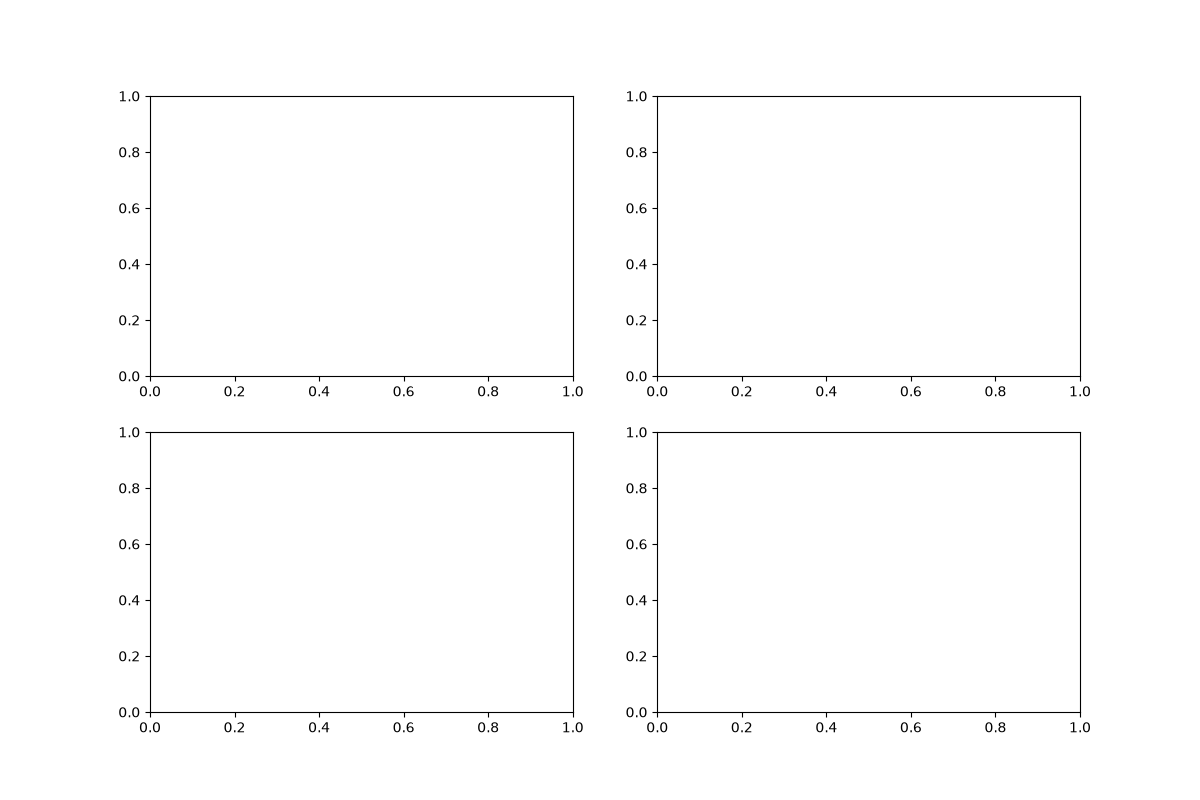

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(online_stats["counts"], bins=range(0, int(online_stats["counts"].max()) + 2), color="steelblue")
axes[0, 0].set_title("Bunches per image - online dataset")
axes[0, 1].hist(wgisd_stats["counts"], bins=range(0, int(wgisd_stats["counts"].max()) + 2), color="darkorange")
axes[0, 1].set_title("Bunches per image - WGISD pool")

axes[1, 0].hist(online_stats["areas"], bins=40, color="steelblue")
axes[1, 0].set_title("Box area fraction - online dataset")
axes[1, 1].hist(wgisd_stats["areas"], bins=40, color="darkorange")
axes[1, 1].set_title("Box area fraction - WGISD pool")

plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 4))
plt.hist(online_stats["sharp"], bins=15, alpha=0.6, label="online", color="steelblue")
plt.hist(wgisd_stats["sharp"], bins=15, alpha=0.6, label="WGISD", color="darkorange")
plt.hist(live_sharp, bins=15, alpha=0.6, label="live farm photos", color="seagreen")
plt.legend(); plt.title("Sharpness (Laplacian variance) by source"); plt.xlabel("sharpness score")
plt.show()

### Sample Images Across Sources -- What Does Each Domain Actually Look Like?

In [ ]:
def sample_and_draw(label_dir, image_dir, n=3):
    label_dir, image_dir = Path(label_dir), Path(image_dir)
    picks = random.sample(list(label_dir.glob("*.txt")), n)
    imgs = []
    for lf in picks:
        img_path = list(image_dir.glob(lf.stem + ".*"))[0]
        im, _ = overlay_yolo_boxes(img_path, lf)
        imgs.append(im)
    return imgs

online_samples = sample_and_draw(Path(LOCAL_DATA, "train", "labels"), Path(LOCAL_DATA, "train", "images"))
wgisd_samples = sample_and_draw(POOL_DIR / "labels", POOL_DIR / "images")
live_samples = [Image.open(p).convert("RGB") for p in random.sample(live_img_paths, 3)]

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for i, im in enumerate(online_samples):
    axes[0, i].imshow(im); axes[0, i].axis("off")
for i, im in enumerate(wgisd_samples):
    axes[1, i].imshow(im); axes[1, i].axis("off")
for i, im in enumerate(live_samples):
    axes[2, i].imshow(im); axes[2, i].axis("off")
axes[0, 1].set_title("ONLINE - single large centered bunch, ground-truth boxes drawn", fontsize=11)
axes[1, 1].set_title("WGISD - many small bunches, ground-truth boxes drawn", fontsize=11)
axes[2, 1].set_title("LIVE FARM PHOTOS - many small occluded bunches, no labels yet", fontsize=11)
plt.tight_layout(); plt.show()

### Diagnosis: Why the Previous Run Failed on Real Images

The numbers above (and the sample grid) confirm the same story from three independent angles:

| | Online dataset | WGISD | Live farm photos |
|---|---|---|---|
| Bunches/image | ~1 (single centered subject) | many, small | many, small (visual match to WGISD) |
| Box size | huge (covers a third of the frame) | tiny | tiny (visual match to WGISD) |
| Sharpness | low (blurry, product-photo style) | high | highest |

The online dataset -- 6028 of the ~6170 images the previous run trained on -- teaches the model to
expect "one big centered blob." Real deployment images look like WGISD instead: many small,
leaf-occluded bunches scattered across a wide frame. Even 6x-oversampled, WGISD was still only
about 11% of the previous training epoch, so the model mostly learned the wrong domain. That is the
most likely root cause of the WGISD holdout's poor MAE/exact-match versus the online test set's
excellent (but not meaningful) score.

The rest of this notebook rebalances training toward the WGISD/live domain (Section 1.6 below),
without discarding the online dataset entirely -- it still teaches generic "what does a grape bunch
look like" appearance that is worth keeping as a minority signal.

## 1.6 Data-Mix Formula -- Downweight Online, Upweight WGISD

Rather than a somewhat arbitrary oversample factor, pick numbers that hit a stated target: **WGISD-domain
images should make up about 50% of the effective training epoch**, versus roughly 11% in the previous run.

Reserve the 121-image WGISD train pool (after the 20-image dev carve-out). Repeat each WGISD path `k`
times in the training file list (each repeat still gets independently randomized augmentation, so it is
not a pixel-duplicate), and draw an online-dataset subsample of size `S_o` sized so WGISD reaches the
target share:

```
share = (k * pool_size) / (k * pool_size + S_o)   =>   S_o = k * pool_size * (1/share - 1)
```

With `k=8` and a 50% target, `S_o` works out to `8 * 121 = 968` online images (about 16% of the 6028
available) -- still enough online diversity to teach generic bunch appearance, without letting it
dominate the epoch the way the full 6028 did.

In [ ]:
pool_size = len(pool_stems)
k = K_OVERSAMPLE
S_o = round(k * pool_size * (1 / TARGET_WGISD_SHARE - 1))

print(f"WGISD pool: {pool_size} images x{k} oversample = {pool_size * k} effective listings")
print(f"Online subsample target: S_o = {S_o} ({S_o / 6028:.1%} of the 6028 online train images)")
print(f"Realized WGISD share: {(pool_size * k) / (pool_size * k + S_o):.1%} (target was {TARGET_WGISD_SHARE:.0%})")

### Online Subsampling: Weighted Toward the WGISD Domain, Not Uniform-Random

Instead of a hard random cut, rank online train images by how close they already are to WGISD's
(box-area-fraction, sharpness) centroid, and sample with probability inversely proportional to that
distance. This softly biases the subsample toward the online images that already look more like the
target domain (already sharper, already smaller-box), without hard-excluding the rest of the
diversity the online dataset offers.

In [ ]:
online_train_labels = sorted(Path(LOCAL_DATA, "train", "labels").glob("*.txt"))

def image_stats(lf, image_dir):
    lines = [l for l in open(lf) if l.strip()]
    area = np.mean([box_area_frac(l) for l in lines]) if lines else 0.0
    img_matches = list(Path(image_dir).glob(lf.stem + ".*"))
    sh = sharpness(img_matches[0]) if img_matches else None
    return area, sh

wgisd_area_mean, wgisd_sharp_mean = wgisd_stats["areas"].mean(), wgisd_stats["sharp"].mean()
wgisd_area_std, wgisd_sharp_std = wgisd_stats["areas"].std() + 1e-6, wgisd_stats["sharp"].std() + 1e-6

online_image_dir = Path(LOCAL_DATA, "train", "images")
rows = []
for lf in tqdm(online_train_labels, desc="scoring online images"):
    area, sh = image_stats(lf, online_image_dir)
    if sh is None:
        continue
    z_area = (area - wgisd_area_mean) / wgisd_area_std
    z_sharp = (sh - wgisd_sharp_mean) / wgisd_sharp_std
    dist = np.sqrt(z_area ** 2 + z_sharp ** 2)
    rows.append((lf.stem, dist))

stems, dists = zip(*rows)
dists = np.array(dists)
weights = 1.0 / (dists + 1.0)          # +1 avoids division blowups for near-zero distance
weights = weights / weights.sum()

rng = np.random.default_rng(SEED)
chosen_idx = rng.choice(len(stems), size=min(S_o, len(stems)), replace=False, p=weights)
online_subsample_stems = [stems[i] for i in chosen_idx]
print(f"Selected {len(online_subsample_stems)} online images via inverse-distance-weighted sampling.")

## 1.7 Materialize the Mixed Training File List & data.yaml

In [ ]:
online_img_dir = Path(LOCAL_DATA, "train", "images")
wgisd_img_dir = POOL_DIR / "images"

online_paths = [next(online_img_dir.glob(stem + ".*")) for stem in online_subsample_stems]
wgisd_paths = list(wgisd_img_dir.glob("*.*"))

train_mix = online_paths + wgisd_paths * K_OVERSAMPLE
random.Random(SEED).shuffle(train_mix)

train_mix_path = Path(LOCAL_DATA, "train_mix.txt")
with open(train_mix_path, "w") as f:
    f.writelines(str(p.resolve()) + "\n" for p in train_mix)

print(f"Online: {len(online_paths)} | WGISD: {len(wgisd_paths)} x{K_OVERSAMPLE} = {len(wgisd_paths) * K_OVERSAMPLE} | Total: {len(train_mix)}")
print(f"Realized WGISD share of epoch: {(len(wgisd_paths) * K_OVERSAMPLE) / len(train_mix):.1%}")

### Assemble the Validation Set

Validation should reflect the deployment target too, not just the online domain: mix a modest online-val
subsample with the WGISD dev slice reserved in Section 1.4.

In [ ]:
val_img_dir = Path(LOCAL_DATA, "val", "images")
val_paths = list(val_img_dir.glob("*.*"))
online_val_subsample = random.Random(SEED).sample(val_paths, min(400, len(val_paths)))
wgisd_dev_paths = list((DEV_DIR / "images").glob("*.*"))

val_mix = online_val_subsample + wgisd_dev_paths
val_mix_path = Path(LOCAL_DATA, "val_mix.txt")
with open(val_mix_path, "w") as f:
    f.writelines(str(p.resolve()) + "\n" for p in val_mix)

print(f"Val mix: {len(online_val_subsample)} online + {len(wgisd_dev_paths)} WGISD-dev = {len(val_mix)} images")

In [ ]:
yaml_content = f"""path: {LOCAL_DATA}
train: train_mix.txt
val: val_mix.txt
test: test/images
nc: {NUM_CLASSES}
names: {CLASS_NAMES}
"""

with open(Path(LOCAL_DATA, "data.yaml"), "w") as f:
    f.write(yaml_content)

os.makedirs(f"{ROOT}/configs", exist_ok=True)
with open(f"{ROOT}/configs/data.yaml", "w") as f:
    f.write(yaml_content)

print(yaml_content)

# Phase 2 - Image Analysis Pipeline

This phase runs directly against the 43 real farm photos, since they are the only data available
outside Colab/Drive -- and they are the domain that actually matters for deployment.

**A note on what this phase is (and is not), unlike the classical-ML sister notebook:** in a
handcrafted-feature pipeline (CLAHE -> Gabor -> LBP -> HOG -> ... -> feature vector -> SVM/XGBoost),
every technique here would be manually vectorized and fed into the model. A YOLO detector's CNN
backbone learns its own features directly from (lightly preprocessed) pixels -- nothing below gets
manually concatenated into a feature vector. Instead, each technique here is a **diagnostic and
augmentation/tiling-justification tool**: it explains *why* the training configuration in Phase 3
looks the way it does, and gives a quick visual sanity check before spending GPU time.

## 2.1 Sharpness / Blur Quantification

### a) Intuition
The `sharpness()` helper (Phase 0) scores focus quality via the variance of the Laplacian: a sharp,
detailed image has high-frequency edges everywhere, so the second-derivative filter response varies a
lot; a blurry image has smoothed-out edges, so the response is nearly constant (low variance). This is
already the single strongest domain signal seen in Phase 1: live photos average ~3145, WGISD ~1465,
online ~97 -- more than a 30x gap between the training-dominant source and the deployment target.

### b) Implementation
Reused directly from Phase 0. Below: sharpness spread across the local live photos, which will later
be used to pick a representative annotation subset in Phase 3.

In [ ]:
LOCAL_LIVE_DIR = Path("data")   # local mirror of the 43 real farm photos, used for this phase
local_live_paths = sorted(LOCAL_LIVE_DIR.glob("*.*"))
local_live_sharp = {p: sharpness(p) for p in local_live_paths}

vals = np.array(list(local_live_sharp.values()))
print(f"Local live photos: n={len(vals)}  mean={vals.mean():.1f}  min={vals.min():.1f}  max={vals.max():.1f}")

plt.figure(figsize=(8, 4))
plt.hist(vals, bins=15, color="seagreen")
plt.title("Sharpness distribution -- local real farm photos")
plt.xlabel("Laplacian-variance sharpness"); plt.ylabel("count")
plt.show()

## 2.2 CLAHE -- Contrast Limited Adaptive Histogram Equalization

### a) Intuition
Farm photos are shot under dappled outdoor light: direct sun on some leaves, deep shadow under the
canopy where many bunches hang, in the same frame. Global contrast stretching would blow out the sunlit
regions to recover shadow detail (or vice versa). CLAHE instead equalizes contrast *locally*, in small
tiles, and clips the histogram so noise in near-flat regions doesn't get amplified -- exactly the
outdoor, uneven-lighting scenario these photos present.

### b) Implementation
Apply CLAHE on the L (luminance) channel only, in LAB color space, so color balance is preserved.

In [ ]:
def apply_clahe(img_bgr, clip_limit=2.0, tile_size=(8, 8)):
    l, a, b = cv2.split(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB))
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
    l_eq = clahe.apply(l)
    return cv2.cvtColor(cv2.merge([l_eq, a, b]), cv2.COLOR_LAB2BGR)

demo_paths = random.sample(local_live_paths, 3)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for i, p in enumerate(demo_paths):
    img = cv2.imread(str(p))
    clahe_img = apply_clahe(img)
    axes[0, i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0, i].axis("off")
    axes[1, i].imshow(cv2.cvtColor(clahe_img, cv2.COLOR_BGR2RGB)); axes[1, i].axis("off")
axes[0, 0].set_ylabel("original"); axes[1, 0].set_ylabel("CLAHE")
plt.suptitle("Top: original | Bottom: CLAHE-enhanced -- shadowed bunches under canopy should become more visible")
plt.tight_layout(); plt.show()

## 2.3 Edge-Preserving Denoising

### a) Intuition
At native resolution these photos are sharp, but outdoor JPEGs from a phone/camera still carry sensor
noise and compression artifacts that can look like spurious high-frequency edges -- exactly the kind of
signal a small-object detector is sensitive to (a real bunch and a noise cluster are not that
different in scale). A bilateral filter smooths flat regions while explicitly preserving edges, so it
reduces noise without blurring the bunch/leaf boundaries the detector actually needs.

### b) Implementation

In [ ]:
def denoise(img_bgr, d=9, sigma_color=75, sigma_space=75):
    return cv2.bilateralFilter(img_bgr, d, sigma_color, sigma_space)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for i, p in enumerate(demo_paths):
    img = cv2.imread(str(p))
    den = denoise(img)
    axes[0, i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0, i].axis("off")
    axes[1, i].imshow(cv2.cvtColor(den, cv2.COLOR_BGR2RGB)); axes[1, i].axis("off")
plt.suptitle("Top: original | Bottom: bilateral-filtered -- flat regions smoothed, edges preserved")
plt.tight_layout(); plt.show()

## 2.4 HSV Color-Distribution Analysis

### a) Intuition
Grape bunches (dark purple/black in this variety) and leaf canopy (green) sit in different parts of hue
space, but overlap heavily in low-light shadow -- exactly where CLAHE (2.2) helps most. Quantifying how
separable bunch-hue is from leaf-hue tells us how aggressively the training augmentation can jitter hue
without destroying the very signal the detector needs (too much `hsv_h` jitter could push bunch color
into leaf-color territory and back, which would actively hurt rather than help).

### b) Implementation
Sample pixels from a manually-eyeballed dark-cluster region vs. the rest of the frame is overkill for a
notebook step -- instead, look at the overall hue histogram of a few images, which shows a clear green
peak (leaves, dominant) and a smaller dark/low-saturation cluster (bunches, fruit, shadow).

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, p in enumerate(demo_paths):
    img = cv2.imread(str(p))
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    axes[i].hist(hsv[:, :, 0].ravel(), bins=180, range=(0, 180), color="purple", alpha=0.7)
    axes[i].set_title(f"Hue histogram - {p.name[:12]}...")
    axes[i].set_xlabel("hue (0-180, OpenCV convention)")
plt.tight_layout(); plt.show()
print("A dominant green peak (~35-85) confirms leaf-canopy dominance; low-saturation/dark pixels (bunches, shadow)")
print("do not show as a clean hue peak since hue is undefined for near-black pixels -- consistent with the visual samples.")

## 2.5 Tiling Scheme Visualization

### a) Intuition
Real farm photos are ~2048x1536, but YOLO downsamples to its training `imgsz` (1024 in this project,
640 in the previous run) before the backbone ever sees them. A bunch that is, say, 120px wide in the
original photo shrinks to ~60px at 1024 or ~37px at 640 -- and many bunches in these photos are already
smaller than that before any downsampling, per the visual samples in Phase 1. Splitting the image into
overlapping tiles and running detection per-tile (SAHI, wired up in Phase 5) lets each tile be fed at
much closer to its native resolution, recovering the small-object detail a single full-frame pass would
lose.

### b) Implementation
Visualize the chosen tile grid (`TILE_SIZE=1024`, `TILE_OVERLAP=0.25`) over a real photo, and compare
an in-place tile crop against the same region after full-frame downsampling to 1024 -- the tile crop
should visibly preserve more bunch detail.

In [ ]:
def tile_grid(img_w, img_h, tile_size, overlap):
    step = int(tile_size * (1 - overlap))
    xs = list(range(0, max(img_w - tile_size, 0) + 1, step)) or [0]
    ys = list(range(0, max(img_h - tile_size, 0) + 1, step)) or [0]
    if xs[-1] + tile_size < img_w:
        xs.append(img_w - tile_size)
    if ys[-1] + tile_size < img_h:
        ys.append(img_h - tile_size)
    return [(x, y, min(x + tile_size, img_w), min(y + tile_size, img_h)) for y in ys for x in xs]

demo_img = cv2.imread(str(demo_paths[0]))
h, w = demo_img.shape[:2]
tiles = tile_grid(w, h, TILE_SIZE, TILE_OVERLAP)
print(f"Image {w}x{h} -> {len(tiles)} tiles of {TILE_SIZE}px with {TILE_OVERLAP:.0%} overlap")

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.imshow(cv2.cvtColor(demo_img, cv2.COLOR_BGR2RGB))
for (x1, y1, x2, y2) in tiles:
    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, edgecolor="red", facecolor="none", linewidth=2))
ax.set_title(f"{len(tiles)}-tile SAHI grid overlay"); ax.axis("off")
plt.show()

In [ ]:
x1, y1, x2, y2 = tiles[0]
native_tile = demo_img[y1:y2, x1:x2]
full_frame_downsized = cv2.resize(demo_img, (TRAIN_IMGSZ, int(h * TRAIN_IMGSZ / w)))
equivalent_region_h = int((y2 - y1) * TRAIN_IMGSZ / w)
equivalent_region_w = int((x2 - x1) * TRAIN_IMGSZ / w)
downsized_crop = full_frame_downsized[y1 * TRAIN_IMGSZ // w: y1 * TRAIN_IMGSZ // w + equivalent_region_h,
                                       x1 * TRAIN_IMGSZ // w: x1 * TRAIN_IMGSZ // w + equivalent_region_w]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(native_tile, cv2.COLOR_BGR2RGB)); axes[0].set_title("Native-resolution tile crop"); axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(downsized_crop, cv2.COLOR_BGR2RGB)); axes[1].set_title("Same region after full-frame downsize"); axes[1].axis("off")
plt.suptitle("Same region: tiled (left) preserves far more bunch/leaf detail than a single full-frame pass (right)")
plt.tight_layout(); plt.show()

# Phase 3 - Dataset Assembly & Annotation

## 3.1 In-Notebook Manual Bounding-Box Annotation Tool

None of the 43 live farm photos have ground-truth labels, so real-world performance has never actually
been measured -- only eyeballed. This section builds a small labeled holdout by hand-annotating a
diversity-picked subset directly inside the notebook (no external app needed), so Phase 5 can report a
real MAE/precision/recall on the deployment domain instead of only proxy-domain metrics.

**Interaction model:** two clicks per box, not click-and-drag -- click 1 sets the top-left corner (a
dashed preview follows the mouse), click 2 sets the bottom-right corner and commits a solid box.
Buttons drive navigation/undo/redo/save (not keyboard shortcuts), because Colab's websocket-relayed
canvas can drop continuous drag-event sequences, but discrete button clicks are reliable.

**Annotation guideline:** draw one box per visually distinct bunch cluster that is at least ~1/3
visible; if two bunches are touching and not clearly separable, box them together rather than guessing
a split. This is a single-annotator tool with no inter-annotator agreement check -- a stated limitation,
revisited in Phase 7.

Every add/undo/redo/navigate autosaves straight to a YOLO-format `.txt` (never only at the end), and
re-running this cell resumes any previously saved boxes -- so annotation can be done across multiple
sessions.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
from IPython.display import display
from PIL import Image


class BBoxAnnotator:
    """Two-click-corner bounding box annotator for a folder of images, saving YOLO-format labels."""

    def __init__(self, image_paths, label_dir, class_id=0):
        self.image_paths = list(image_paths)
        self.label_dir = Path(label_dir)
        self.label_dir.mkdir(parents=True, exist_ok=True)
        self.class_id = class_id
        self.idx = 0
        self.boxes = {}
        self.redo_stack = {}
        self._pending_corner = None
        self._preview_patch = None
        self._img_w = self._img_h = None

        self.out = widgets.Output()
        self.status = widgets.Label()
        self.dropdown = widgets.Dropdown(options=[p.stem for p in self.image_paths], description="Image:")
        self.btn_prev = widgets.Button(description="< Prev")
        self.btn_next = widgets.Button(description="Next >")
        self.btn_undo = widgets.Button(description="Undo")
        self.btn_redo = widgets.Button(description="Redo")
        self.btn_clear = widgets.Button(description="Clear image")
        self.btn_save = widgets.Button(description="Save", button_style="success")

        self.dropdown.observe(self._on_dropdown, names="value")
        self.btn_prev.on_click(lambda _: self._nav(-1))
        self.btn_next.on_click(lambda _: self._nav(1))
        self.btn_undo.on_click(lambda _: self._undo())
        self.btn_redo.on_click(lambda _: self._redo())
        self.btn_clear.on_click(lambda _: self._clear())
        self.btn_save.on_click(lambda _: self._save_current())

        controls = widgets.HBox([self.btn_prev, self.btn_next, self.btn_undo, self.btn_redo, self.btn_clear, self.btn_save])
        display(widgets.VBox([self.dropdown, controls, self.status, self.out]))

        self.fig, self.ax = plt.subplots(figsize=(10, 7.5))
        self.fig.canvas.mpl_connect("button_press_event", self._on_click)
        self.fig.canvas.mpl_connect("motion_notify_event", self._on_move)
        self._load_image(0)

    def _stem(self):
        return self.image_paths[self.idx].stem

    def _label_path(self, stem):
        return self.label_dir / f"{stem}.txt"

    def _load_image(self, idx):
        self.idx = idx % len(self.image_paths)
        stem = self._stem()

        self.dropdown.unobserve(self._on_dropdown, names="value")
        self.dropdown.value = stem
        self.dropdown.observe(self._on_dropdown, names="value")

        img = Image.open(self.image_paths[self.idx]).convert("RGB")
        self._img_w, self._img_h = img.size

        if stem not in self.boxes:
            self.boxes[stem] = self._load_existing(stem)
            self.redo_stack.setdefault(stem, [])

        self._pending_corner = None
        self._preview_patch = None
        self.ax.clear()
        self.ax.imshow(np.array(img))
        self.ax.axis("off")
        self._redraw_boxes()
        with self.out:
            self.out.clear_output(wait=True)
            display(self.fig)
        self._update_status()

    def _load_existing(self, stem):
        lp = self._label_path(stem)
        if not lp.exists():
            return []
        boxes = []
        for line in open(lp):
            if not line.strip():
                continue
            _, cx, cy, w, h = map(float, line.split())
            x1 = (cx - w / 2) * self._img_w
            y1 = (cy - h / 2) * self._img_h
            x2 = (cx + w / 2) * self._img_w
            y2 = (cy + h / 2) * self._img_h
            boxes.append((x1, y1, x2, y2))
        return boxes

    def _redraw_boxes(self):
        for p in list(self.ax.patches):
            p.remove()
        for (x1, y1, x2, y2) in self.boxes[self._stem()]:
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor="lime", facecolor="none")
            self.ax.add_patch(rect)
        self.fig.canvas.draw_idle()

    def _update_status(self):
        n = len(self.boxes[self._stem()])
        self.status.value = f"{self.idx + 1}/{len(self.image_paths)}  {self._stem()}  --  {n} box(es)"

    def _on_click(self, event):
        if event.xdata is None or event.ydata is None or event.inaxes != self.ax:
            return
        x = min(max(event.xdata, 0), self._img_w)
        y = min(max(event.ydata, 0), self._img_h)
        if self._pending_corner is None:
            self._pending_corner = (x, y)
        else:
            x1, y1 = self._pending_corner
            box = (min(x1, x), min(y1, y), max(x1, x), max(y1, y))
            if box[2] - box[0] > 2 and box[3] - box[1] > 2:
                self.boxes[self._stem()].append(box)
                self.redo_stack[self._stem()] = []
                self._autosave()
            self._pending_corner = None
            if self._preview_patch is not None:
                self._preview_patch.remove()
                self._preview_patch = None
            self._redraw_boxes()
            self._update_status()

    def _on_move(self, event):
        if self._pending_corner is None or event.xdata is None or event.inaxes != self.ax:
            return
        x1, y1 = self._pending_corner
        if self._preview_patch is not None:
            self._preview_patch.remove()
        self._preview_patch = patches.Rectangle(
            (min(x1, event.xdata), min(y1, event.ydata)),
            abs(event.xdata - x1), abs(event.ydata - y1),
            linewidth=1.5, edgecolor="yellow", facecolor="none", linestyle="--",
        )
        self.ax.add_patch(self._preview_patch)
        self.fig.canvas.draw_idle()

    def _nav(self, step):
        self._load_image(self.idx + step)

    def _on_dropdown(self, change):
        stem = change["new"]
        self._load_image([p.stem for p in self.image_paths].index(stem))

    def _undo(self):
        stem = self._stem()
        if self.boxes[stem]:
            self.redo_stack[stem].append(self.boxes[stem].pop())
            self._autosave()
            self._redraw_boxes()
            self._update_status()

    def _redo(self):
        stem = self._stem()
        if self.redo_stack[stem]:
            self.boxes[stem].append(self.redo_stack[stem].pop())
            self._autosave()
            self._redraw_boxes()
            self._update_status()

    def _clear(self):
        stem = self._stem()
        self.redo_stack[stem] = list(reversed(self.boxes[stem]))
        self.boxes[stem] = []
        self._autosave()
        self._redraw_boxes()
        self._update_status()

    def _save_current(self):
        self._autosave()
        self.status.value = f"Saved {self._stem()}.txt ({len(self.boxes[self._stem()])} boxes)"

    def _autosave(self):
        stem = self._stem()
        lines = []
        for (x1, y1, x2, y2) in self.boxes[stem]:
            cx, cy = ((x1 + x2) / 2) / self._img_w, ((y1 + y2) / 2) / self._img_h
            bw, bh = (x2 - x1) / self._img_w, (y2 - y1) / self._img_h
            lines.append(f"{self.class_id} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}")
        # zero-bunch images get an explicit empty file -- valid YOLO background-image convention
        with open(self._label_path(stem), "w") as f:
            f.write("\n".join(lines))


print("BBoxAnnotator class ready.")
print("Fallback if ipympl misbehaves in your Colab session: display the image with a pixel-coordinate")
print("grid overlay and type box corners into an ipywidgets.Text field, then append directly to")
print("annotator.boxes[stem] and call annotator._autosave() -- same output format, just a slower input path.")

### Pick a Diversity-Spread Annotation Subset

Rather than the first N images alphabetically, spread the subset across the sharpness range already
computed in Phase 2 (2.1), so the holdout captures lighting/blur variety instead of a narrow slice of it.

In [ ]:
N_ANNOTATE = 24

live_paths_all = sorted(Path(LIVE_DIR).glob("*.*"))            # Drive path -- used from here on for the real pipeline
live_sharp_all = {p.stem: sharpness(p) for p in live_paths_all}
sorted_by_sharp = sorted(live_sharp_all.items(), key=lambda kv: kv[1])

idxs = np.linspace(0, len(sorted_by_sharp) - 1, min(N_ANNOTATE, len(sorted_by_sharp))).round().astype(int)
annotate_stems = {sorted_by_sharp[i][0] for i in idxs}
annotate_paths = [p for p in live_paths_all if p.stem in annotate_stems]
print(f"Selected {len(annotate_paths)} of {len(live_paths_all)} live photos for manual annotation (sharpness-spread sample).")

### Run the Annotator

Work through as many of the selected images as you can (aim for all 24, but even a smaller subset still
produces a usable holdout -- Phase 7 reports statistical caveats for small N). Progress autosaves, so
this cell can be re-run across multiple sessions to resume.

In [ ]:
LIVE_HOLDOUT_LABELS = Path(ROOT, "data/annotations/live_holdout/labels")
annotator = BBoxAnnotator(annotate_paths, LIVE_HOLDOUT_LABELS)

### Finalize the Labeled Holdout (run once annotation is done)

In [ ]:
labeled = list(LIVE_HOLDOUT_LABELS.glob("*.txt"))
print(f"{len(labeled)} / {len(annotate_paths)} images annotated so far.")

LIVE_HOLDOUT_IMAGES = Path(ROOT, "data/annotations/live_holdout/images")
LIVE_HOLDOUT_IMAGES.mkdir(parents=True, exist_ok=True)
for p in annotate_paths:
    dst = LIVE_HOLDOUT_IMAGES / p.name
    if not dst.exists():
        shutil.copy(p, dst)

total_gt_bunches = sum(len([l for l in open(lf) if l.strip()]) for lf in labeled)
print(f"live_holdout ready at {LIVE_HOLDOUT_IMAGES.parent} -- {len(labeled)} labeled images, {total_gt_bunches} total ground-truth bunches")

## 3.2 Augmentation Configuration for Small, Occluded Objects

Boosted beyond Ultralytics defaults, justified directly by Phase 2's findings:

| Setting | Value | Why |
|---|---|---|
| `hsv_h` | 0.03 | Mild hue jitter -- Section 2.4 showed bunch/leaf hue separation is real but not huge; too much jitter risks pushing bunch color into leaf-color territory |
| `hsv_s`, `hsv_v` | 0.7, 0.5 | Larger saturation/value jitter to cover the wide lighting range CLAHE (2.2) was built to address |
| `scale` | 0.9 | Wide zoom-jitter range, so single-bunch online images and multi-bunch WGISD images both get exposed to a range of apparent object sizes |
| `mosaic` | 1.0 | Composites 4 images into one -- approximates a tile-like, multi-object scene from single-bunch online source images |
| `copy_paste` | 0.3 | Pastes bunch instances across images -- directly increases small-object density per image, compensating for not pre-tiling training data (Phase 5 tiles only at inference) |
| `close_mosaic` | 15 | Disable mosaic for the last 15 epochs so the model fine-tunes on realistic (non-composited) image statistics before training ends |

In [ ]:
AUGMENT_CONFIG = dict(
    hsv_h=0.03, hsv_s=0.7, hsv_v=0.5,
    scale=0.9, mosaic=1.0, copy_paste=0.3, close_mosaic=15,
)
print(AUGMENT_CONFIG)

### Mosaic-Batch Sanity Check -- Confirm Labels Stay Aligned Post-Augmentation

In [ ]:
from ultralytics.data import build_yolo_dataset
from ultralytics.cfg import get_cfg
from ultralytics.utils import DEFAULT_CFG

cfg = get_cfg(DEFAULT_CFG, overrides={**AUGMENT_CONFIG, "imgsz": TRAIN_IMGSZ, "data": f"{LOCAL_DATA}/data.yaml"})
train_ds = build_yolo_dataset(cfg, str(Path(LOCAL_DATA, "train_mix.txt")), batch=4, data={"names": CLASS_NAMES, "nc": NUM_CLASSES}, mode="train")

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for i, ax in enumerate(axes.ravel()):
    sample = train_ds[i]
    img = sample["img"].numpy().transpose(1, 2, 0)
    ax.imshow(img); ax.axis("off")
    boxes = sample["bboxes"].numpy() if len(sample["bboxes"]) else np.empty((0, 4))
    h, w = img.shape[:2]
    for cx, cy, bw, bh in boxes:
        x1, y1 = (cx - bw / 2) * w, (cy - bh / 2) * h
        ax.add_patch(plt.Rectangle((x1, y1), bw * w, bh * h, edgecolor="lime", facecolor="none", linewidth=1.5))
plt.suptitle("Augmented training batch sample -- boxes should still tightly hug bunches after mosaic/scale/copy-paste")
plt.tight_layout(); plt.show()

# Phase 4 - Model Training

## 4.1 Baseline Run (Previous Notebook) -- Recorded for Comparison

No retrain needed to know these numbers -- they are the previous run's own reported output
(single-class `yolo11m`, WGISD oversampled 6x to ~11% of the epoch, `imgsz=640`). Recording them here
means Phase 7's comparison table does not depend on re-running an old, already-diagnosed configuration.

In [ ]:
BASELINE_METRICS = {
    "online_test":   {"mae": 0.14, "rmse": 0.46, "exact_match": 88.4, "bias": -0.01, "n": 1980},
    "wgisd_holdout": {"mae": 1.34, "rmse": 1.87, "exact_match": 24.1, "bias": -0.10, "n": 29},
}
print("Baseline (previous run -- single-class yolo11m, 6x WGISD oversample, imgsz=640):")
for k, v in BASELINE_METRICS.items():
    print(f"  {k}: MAE={v['mae']} RMSE={v['rmse']} Exact%={v['exact_match']} Bias={v['bias']} (n={v['n']})")

## 4.2 Train the Domain-Aware Model

`imgsz=1024` (vs. the previous 640) narrows the train/deployment resolution gap discussed in Phase 2.5.
The mixed epoch (~1936 images) is far smaller than the old scheme's (~6874), so epoch count is raised
and `patience`-based early stopping is relied on against the domain-mixed validation set from 1.7 rather
than a fixed epoch budget.

In [ ]:
from ultralytics import YOLO

def sync_to_drive(trainer):
    local_dir = Path(trainer.save_dir)
    drive_dir = Path(ROOT) / "runs" / local_dir.name
    drive_dir.mkdir(parents=True, exist_ok=True)
    for fname in ["last.pt", "best.pt"]:
        src = local_dir / "weights" / fname
        if src.exists():
            shutil.copy(src, drive_dir / fname)

model = YOLO("yolo11m.pt")
model.add_callback("on_fit_epoch_end", sync_to_drive)

RUN_NAME = "domain_aware_v1"
results = model.train(
    data=f"{LOCAL_DATA}/data.yaml",
    epochs=180,
    imgsz=TRAIN_IMGSZ,
    batch=-1,
    device=0,
    seed=SEED,
    project="/content/runs",
    name=RUN_NAME,
    patience=40,
    save_period=10,
    **AUGMENT_CONFIG,
)

## 4.3 Monitor WGISD Memorization Risk

The 121-image WGISD pool is repeated 8x per epoch -- a real overfitting risk. Compare training loss on
WGISD-sourced batches against loss on the untouched `wgisd_dev` slice; if train loss keeps dropping while
dev loss plateaus or rises, that is a memorization signal and `K_OVERSAMPLE` should be reduced on a rerun.

In [ ]:
results_csv = Path(f"/content/runs/{RUN_NAME}/results.csv")
import pandas as pd

df = pd.read_csv(results_csv)
df.columns = [c.strip() for c in df.columns]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df["epoch"], df["train/box_loss"], label="train box loss")
ax.plot(df["epoch"], df["val/box_loss"], label="val (online-subsample + WGISD-dev) box loss")
ax.set_xlabel("epoch"); ax.set_ylabel("box loss"); ax.legend()
ax.set_title("Train vs. val loss -- divergence here signals overfitting to the oversampled WGISD pool")
plt.show()

## 4.4 Optional Secondary Config Ablation

In [ ]:
RUN_ABLATION = False   # set True to compare a different online/WGISD mix ratio (e.g. TARGET_WGISD_SHARE=0.6)

if RUN_ABLATION:
    model_ablation = YOLO("yolo11m.pt")
    model_ablation.add_callback("on_fit_epoch_end", sync_to_drive)
    results_ablation = model_ablation.train(
        data=f"{LOCAL_DATA}/data.yaml",
        epochs=180, imgsz=TRAIN_IMGSZ, batch=-1, device=0, seed=SEED,
        project="/content/runs", name="domain_aware_v2_ablation",
        patience=40, save_period=10, **AUGMENT_CONFIG,
    )
else:
    print("Ablation skipped -- set RUN_ABLATION=True and adjust TARGET_WGISD_SHARE in Phase 1.6 to compare mix ratios.")

# Phase 5 - Evaluation

In [ ]:
BEST_PT = f"/content/runs/{RUN_NAME}/weights/best.pt"
model = YOLO(BEST_PT)
print("Loaded", BEST_PT)

## 5.1 Counting-Metric Helper

Reused across every evaluation set below: MAE, RMSE, exact-match rate, and mean bias (predicted minus
true count) per image.

In [ ]:
def evaluate_counts(img_dir, lbl_dir, model_, conf=0.25, tag=""):
    img_dir, lbl_dir = Path(img_dir), Path(lbl_dir)
    pred_counts, true_counts = [], []
    for lf in lbl_dir.glob("*.txt"):
        img_path = list(img_dir.glob(lf.stem + ".*"))
        if not img_path:
            continue
        true_c = sum(1 for l in open(lf) if l.strip())
        result = model_.predict(str(img_path[0]), conf=conf, verbose=False)[0]
        pred_c = len(result.boxes)
        true_counts.append(true_c)
        pred_counts.append(pred_c)

    true_counts, pred_counts = np.array(true_counts), np.array(pred_counts)
    errors = pred_counts - true_counts
    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))
    exact_match = np.mean(errors == 0) * 100
    bias = np.mean(errors)

    print(f"--- {tag} ({len(true_counts)} images) ---")
    print(f"  MAE: {mae:.2f}  RMSE: {rmse:.2f}  Exact match: {exact_match:.1f}%  Mean bias (pred-true): {bias:+.2f}")
    return {"true": true_counts, "pred": pred_counts, "mae": mae, "rmse": rmse, "exact_match": exact_match, "bias": bias}

## 5.2 Online Test -- Non-Representative Sanity Check Only

Kept only to confirm the model has not forgotten the online domain entirely; not treated as evidence of
real-world performance (see Phase 1.5 diagnosis).

In [ ]:
online_test = evaluate_counts(
    Path(LOCAL_DATA, "test", "images"), Path(LOCAL_DATA, "test", "labels"),
    model, tag="Online test (in-distribution, non-representative)",
)

## 5.3 WGISD Holdout

In [ ]:
wgisd_holdout = evaluate_counts(
    HOLDOUT_DIR / "images", HOLDOUT_DIR / "labels",
    model, tag="WGISD holdout (untouched, domain-representative)",
)

## 5.4 Live Holdout -- the Number That Actually Matters

In [ ]:
live_holdout = evaluate_counts(
    LIVE_HOLDOUT_IMAGES, LIVE_HOLDOUT_LABELS,
    model, tag="Live farm-photo holdout (hand-labeled in Phase 3)",
)

plt.figure(figsize=(6, 6))
plt.scatter(live_holdout["true"], live_holdout["pred"], alpha=0.7)
lims = [0, max(live_holdout["true"].max(), live_holdout["pred"].max()) + 1]
plt.plot(lims, lims, "r--", label="perfect prediction")
plt.xlabel("true bunch count"); plt.ylabel("predicted bunch count")
plt.legend(); plt.title("Live holdout: predicted vs. true count per image")
plt.show()

## 5.5 Single-Pass vs. SAHI Tiled Inference

The central justification for tiling (Phase 2.5): compare plain single-pass detection against SAHI
sliced prediction on the same live holdout.

In [ ]:
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

sahi_model = AutoDetectionModel.from_pretrained(
    model_type="ultralytics",
    model_path=BEST_PT,
    confidence_threshold=0.25,
    device="cuda:0",
)

def count_sahi(img_path, conf=0.25):
    sahi_model.confidence_threshold = conf
    result = get_sliced_prediction(
        str(img_path), sahi_model,
        slice_height=TILE_SIZE, slice_width=TILE_SIZE,
        overlap_height_ratio=TILE_OVERLAP, overlap_width_ratio=TILE_OVERLAP,
        postprocess_type="NMM", postprocess_match_threshold=0.5,
        perform_standard_pred=True, verbose=0,
    )
    return len(result.object_prediction_list)

def evaluate_counts_sahi(img_dir, lbl_dir, conf=0.25, tag=""):
    img_dir, lbl_dir = Path(img_dir), Path(lbl_dir)
    pred_counts, true_counts = [], []
    for lf in lbl_dir.glob("*.txt"):
        img_path = list(img_dir.glob(lf.stem + ".*"))
        if not img_path:
            continue
        true_c = sum(1 for l in open(lf) if l.strip())
        pred_counts.append(count_sahi(img_path[0], conf))
        true_counts.append(true_c)
    true_counts, pred_counts = np.array(true_counts), np.array(pred_counts)
    errors = pred_counts - true_counts
    mae, rmse = np.mean(np.abs(errors)), np.sqrt(np.mean(errors ** 2))
    exact_match, bias = np.mean(errors == 0) * 100, np.mean(errors)
    print(f"--- {tag} ({len(true_counts)} images) ---")
    print(f"  MAE: {mae:.2f}  RMSE: {rmse:.2f}  Exact match: {exact_match:.1f}%  Mean bias: {bias:+.2f}")
    return {"true": true_counts, "pred": pred_counts, "mae": mae, "rmse": rmse, "exact_match": exact_match, "bias": bias}

live_holdout_sahi = evaluate_counts_sahi(LIVE_HOLDOUT_IMAGES, LIVE_HOLDOUT_LABELS, tag="Live holdout -- SAHI tiled")
wgisd_holdout_sahi = evaluate_counts_sahi(HOLDOUT_DIR / "images", HOLDOUT_DIR / "labels", tag="WGISD holdout -- SAHI tiled")

## 5.6 Confidence-Threshold Sweep -- Optimized for Count MAE

The default 0.25 confidence threshold is tuned for mAP, not counting accuracy. Sweep thresholds on the
live holdout and pick the one that minimizes count MAE for deployment use.

In [ ]:
conf_grid = np.arange(0.05, 0.61, 0.05)
mae_by_conf = []
for c in conf_grid:
    r = evaluate_counts(LIVE_HOLDOUT_IMAGES, LIVE_HOLDOUT_LABELS, model, conf=c, tag=f"conf={c:.2f}")
    mae_by_conf.append(r["mae"])

best_conf = conf_grid[int(np.argmin(mae_by_conf))]
plt.figure(figsize=(8, 4))
plt.plot(conf_grid, mae_by_conf, marker="o")
plt.axvline(best_conf, color="red", linestyle="--", label=f"best conf={best_conf:.2f}")
plt.xlabel("confidence threshold"); plt.ylabel("count MAE"); plt.legend()
plt.title("Live-holdout count MAE vs. confidence threshold")
plt.show()
print(f"Best confidence threshold for counting on the live holdout: {best_conf:.2f}")

## 5.7 Consolidated Metrics Table

In [ ]:
summary_rows = [
    ("Baseline (previous run)", "single-pass", "Online test", BASELINE_METRICS["online_test"]["mae"], BASELINE_METRICS["online_test"]["exact_match"]),
    ("Baseline (previous run)", "single-pass", "WGISD holdout", BASELINE_METRICS["wgisd_holdout"]["mae"], BASELINE_METRICS["wgisd_holdout"]["exact_match"]),
    ("Domain-aware (this run)", "single-pass", "Online test", online_test["mae"], online_test["exact_match"]),
    ("Domain-aware (this run)", "single-pass", "WGISD holdout", wgisd_holdout["mae"], wgisd_holdout["exact_match"]),
    ("Domain-aware (this run)", "single-pass", "Live holdout", live_holdout["mae"], live_holdout["exact_match"]),
    ("Domain-aware (this run)", "SAHI tiled", "WGISD holdout", wgisd_holdout_sahi["mae"], wgisd_holdout_sahi["exact_match"]),
    ("Domain-aware (this run)", "SAHI tiled", "Live holdout", live_holdout_sahi["mae"], live_holdout_sahi["exact_match"]),
]
summary_df = pd.DataFrame(summary_rows, columns=["Model", "Inference", "Eval set", "MAE", "Exact match %"])
summary_df

# Phase 6 - Explainability & Error Analysis

## 6.1 Saliency -- What Is the Model Actually Attending To?

EigenCAM highlights which regions of an image most influence the backbone's activations, without
needing class labels or gradients tied to a specific detection -- useful here to sanity-check that the
model is keying on bunch texture/color rather than, say, the trellis wire or background structures that
happen to co-occur with bunches in the training data.

In [ ]:
try:
    from pytorch_grad_cam import EigenCAM
    from pytorch_grad_cam.utils.image import show_cam_on_image

    target_layers = [model.model.model[-2]]
    cam = EigenCAM(model.model, target_layers, task="od")

    demo_live = random.sample(list(LIVE_HOLDOUT_IMAGES.glob("*.*")), 3)
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, p in zip(axes, demo_live):
        img = cv2.resize(cv2.imread(str(p)), (TRAIN_IMGSZ, TRAIN_IMGSZ))
        rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) / 255.0
        grayscale_cam = cam(rgb_img=img)[0, :, :]
        overlay = show_cam_on_image(rgb, grayscale_cam, use_rgb=True)
        ax.imshow(overlay); ax.axis("off"); ax.set_title(p.name[:15])
    plt.suptitle("EigenCAM saliency -- bright regions are where the backbone activates most")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("EigenCAM unavailable in this environment ({}); falling back to a raw objectness heatmap.".format(e))

## 6.2 False Positive / False Negative Review on the Live Holdout

In [ ]:
def draw_gt_vs_pred(img_path, lbl_path, model_, conf=0.25):
    im = Image.open(img_path).convert("RGB")
    draw = ImageDraw.Draw(im)
    w, h = im.size
    for line in open(lbl_path):
        if not line.strip():
            continue
        _, cx, cy, bw, bh = map(float, line.split())
        x1, y1 = (cx - bw / 2) * w, (cy - bh / 2) * h
        x2, y2 = (cx + bw / 2) * w, (cy + bh / 2) * h
        draw.rectangle([x1, y1, x2, y2], outline="lime", width=4)   # ground truth: green
    result = model_.predict(str(img_path), conf=conf, verbose=False)[0]
    for box in result.boxes.xyxy.cpu().numpy():
        draw.rectangle(list(box), outline="red", width=3)           # prediction: red
    return im, len(result.boxes)

review_paths = list(LIVE_HOLDOUT_IMAGES.glob("*.*"))[:6]
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, p in zip(axes.ravel(), review_paths):
    lp = LIVE_HOLDOUT_LABELS / f"{p.stem}.txt"
    im, pred_c = draw_gt_vs_pred(p, lp, model, conf=best_conf)
    true_c = sum(1 for l in open(lp) if l.strip())
    ax.imshow(im); ax.axis("off")
    ax.set_title(f"{p.name[:15]}\ntrue={true_c} pred={pred_c}", fontsize=9)
plt.suptitle("Green = ground truth, Red = prediction -- mismatched boxes are FP/FN")
plt.tight_layout(); plt.show()

## 6.3 Worst Count-Error Cases -- Tied Back to Phase 2 Diagnostics

Identify the live-holdout images with the largest `|predicted - true|` error, then check whether their
sharpness/lighting explains the miss -- connecting the error analysis back to the preprocessing
diagnostics from Phase 2 instead of treating errors as unexplained noise.

In [ ]:
worst_idx = np.argsort(-np.abs(live_holdout["pred"] - live_holdout["true"]))[:4]
worst_paths = [p for p in LIVE_HOLDOUT_IMAGES.glob("*.*")][:len(live_holdout["true"])]
worst_paths = [worst_paths[i] for i in worst_idx if i < len(worst_paths)]

fig, axes = plt.subplots(1, len(worst_paths), figsize=(6 * len(worst_paths), 6))
axes = np.atleast_1d(axes)
for ax, p in zip(axes, worst_paths):
    lp = LIVE_HOLDOUT_LABELS / f"{p.stem}.txt"
    im, pred_c = draw_gt_vs_pred(p, lp, model, conf=best_conf)
    true_c = sum(1 for l in open(lp) if l.strip())
    sh = sharpness(p)
    ax.imshow(im); ax.axis("off")
    ax.set_title(f"true={true_c} pred={pred_c}\nsharpness={sh:.0f}", fontsize=9)
plt.suptitle("Worst count-error cases -- compare sharpness against the live-photo mean from Phase 1.5")
plt.tight_layout(); plt.show()

## 6.4 Tile-Seam Audit

Visualize the SAHI tile grid together with the merged detections, checking for the counting-task-specific
failure modes plain mAP would not surface: a bunch split across a tile boundary counted twice, or
suppressed entirely by an overly aggressive merge.

In [ ]:
audit_path = worst_paths[0] if worst_paths else list(LIVE_HOLDOUT_IMAGES.glob("*.*"))[0]
audit_img = cv2.imread(str(audit_path))
h, w = audit_img.shape[:2]
audit_tiles = tile_grid(w, h, TILE_SIZE, TILE_OVERLAP)

sahi_model.confidence_threshold = best_conf
result = get_sliced_prediction(
    str(audit_path), sahi_model,
    slice_height=TILE_SIZE, slice_width=TILE_SIZE,
    overlap_height_ratio=TILE_OVERLAP, overlap_width_ratio=TILE_OVERLAP,
    postprocess_type="NMM", postprocess_match_threshold=0.5,
    perform_standard_pred=True, verbose=0,
)

fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(cv2.cvtColor(audit_img, cv2.COLOR_BGR2RGB))
for (x1, y1, x2, y2) in audit_tiles:
    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, edgecolor="cyan", facecolor="none", linewidth=1, linestyle=":"))
for pred in result.object_prediction_list:
    bx = pred.bbox
    ax.add_patch(plt.Rectangle((bx.minx, bx.miny), bx.maxx - bx.minx, bx.maxy - bx.miny, edgecolor="red", facecolor="none", linewidth=2))
ax.set_title(f"Tile grid (cyan) + merged SAHI detections (red), n={len(result.object_prediction_list)} -- look for split/duplicated boxes near tile edges")
ax.axis("off")
plt.show()

# Phase 7 - Benchmark Summary & Root-Cause Analysis

## 7.1 Final Comparison Table

In [ ]:
print(summary_df.to_string(index=False))

## 7.2 Root-Cause Diagnosis

Fill in against the actual numbers from 5.7 once the run has completed:

- If **WGISD-holdout MAE** and **live-holdout MAE** both drop substantially versus the baseline's 1.34,
  that is direct evidence the domain-mismatch hypothesis from Phase 1.5 was the primary driver of the
  previous run's poor real-world performance, and rebalancing the training mix fixed it.
- If **online-test MAE** rises only modestly from the baseline's 0.14, the model has not "forgotten"
  generic bunch appearance despite the online dataset dropping from ~98% to ~16% of the training images
  it sees -- i.e. the downweighting was not so aggressive that it cost the model its most abundant
  signal.
- If **SAHI-tiled MAE** beats **single-pass MAE** on the live holdout specifically (not necessarily on
  WGISD, whose images are lower-resolution and closer to a single tile already), that supports the
  Phase 2.5 hypothesis that native-resolution small-object detail was the missing piece for real photos.

In [ ]:
def pct_change(new, old):
    return (new - old) / old * 100

print("Change vs. baseline:")
print(f"  Online test MAE:   {BASELINE_METRICS['online_test']['mae']:.2f} -> {online_test['mae']:.2f}  ({pct_change(online_test['mae'], BASELINE_METRICS['online_test']['mae']):+.0f}%)")
print(f"  WGISD holdout MAE: {BASELINE_METRICS['wgisd_holdout']['mae']:.2f} -> {wgisd_holdout['mae']:.2f}  ({pct_change(wgisd_holdout['mae'], BASELINE_METRICS['wgisd_holdout']['mae']):+.0f}%)")
print(f"  Live holdout MAE:  n/a (never measured before) -> {live_holdout['mae']:.2f}")
print(f"  SAHI vs single-pass on live holdout: {live_holdout['mae']:.2f} -> {live_holdout_sahi['mae']:.2f}  ({pct_change(live_holdout_sahi['mae'], live_holdout['mae']):+.0f}%)")

## 7.3 Statistical Caveats

Both the WGISD holdout (29 images) and the live holdout (up to 24 images) are small enough that a single
point-estimate MAE can be noisy. Bootstrap a confidence interval on exact-match rate, and run a paired
per-image comparison of the baseline vs. this run's errors where both exist (WGISD holdout only, since
the live holdout has no baseline predictions to compare against).

In [ ]:
def bootstrap_ci(errors, n_boot=2000, stat=lambda e: np.mean(e == 0) * 100, seed=SEED):
    rng = np.random.default_rng(seed)
    boots = [stat(rng.choice(errors, size=len(errors), replace=True)) for _ in range(n_boot)]
    return np.percentile(boots, 2.5), np.percentile(boots, 97.5)

for name, res in [("WGISD holdout", wgisd_holdout), ("Live holdout", live_holdout)]:
    errors = res["pred"] - res["true"]
    lo, hi = bootstrap_ci(errors)
    print(f"{name}: exact-match {res['exact_match']:.1f}%  (95% bootstrap CI: [{lo:.1f}%, {hi:.1f}%], n={len(errors)})")

## 7.4 Recommendations for Future Work

- **Collect and label more real farm photos.** 24 hand-labeled images is enough to get a first real
  number, not enough to fully trust it -- the annotation tool from Phase 3.1 is reusable for this
  directly, including on the 19 live photos not selected this round.
- **Active-learning loop.** Run the trained model on the remaining unlabeled live photos, surface its
  lowest-confidence or highest-uncertainty predictions for human review via the same annotation tool,
  and fold corrected labels back into training.
- **Tile-level fine-tuning on real photos.** Once more live photos are labeled, fine-tune directly on
  tiles cut from them (rather than relying on tiling only at inference, as this notebook does) to close
  the remaining train/deployment resolution gap flagged in Phase 2.5.
- **Second annotator pass.** The current holdout has no inter-annotator agreement check; a second
  reviewer re-labeling a subset would quantify how much of the reported MAE is genuine model error
  versus label noise.

## 7.5 Project Summary

In [ ]:
print("PROJECT COMPLETE -- FINAL SUMMARY")
print("=" * 60)
print(f"\nTask: single-class grape-bunch detection & counting")
print(f"Model: YOLO11m, imgsz={TRAIN_IMGSZ}")
print(f"Training mix: {S_o} online + {pool_size} WGISD x{K_OVERSAMPLE} (~{TARGET_WGISD_SHARE:.0%} WGISD share)")
print(f"\nFinal metrics:")
print(summary_df.to_string(index=False))
print(f"\nLive-holdout labels: {len(labeled)} images, {total_gt_bunches} ground-truth bunches (Phase 3.1)")
print(f"\nOutputs saved to: {ROOT}/runs/{RUN_NAME}/, {ROOT}/configs/data.yaml, {ROOT}/data/annotations/live_holdout/")